# Švihadlo a fotony, pokročilá verze: kolik fotonů zachytí pixel Sentinelu-2 a dronu

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Švihadlo a fotony](https://openskylab.space/edu_viz_rope_and_photons.html) · [English version](rope_and_photons_pro_en.ipynb)

Pokročilá verze notebooku o fotonech. Ze skutečné scény Sentinel-2 nad Roztoky spočítáš, kolik fotonů dopadne za dobu přeletu jednoho pixelu na detektor v pásmech B02, B04, B08 a B11, jaký z toho plyne odstup signálu od šumu a jak ho mění velikost dalekohledu. Pak stejný výpočet uděláš pro kameru na dronu a zjistíš, proč malý objektiv nízko nad zemí sbírá podobně mnoho fotonů jako dalekohled na dráze.

**Cíl:** z odrazivosti L1C spočítat zář a počet fotoelektronů v pixelu, odvodit odstup signálu od šumu √N, nasimulovat fotonový šum pro různé pupily, porovnat družici s dronem přes součin A·Ω a ověřit, jak SNR roste se slučováním pixelů a jak se má ke kvantování.

**Data:** Copernicus Sentinel-2B L1C `S2B_MSIL1C_20240721T100559_N0510_R022_T33UVR_20240721T121133` (21. 7. 2024) z veřejného archivu Google Cloud: metadata MTD_MSIL1C a MTD_TL a výřezy 4 × 4 km pásem B02, B04, B08 a B11 kolem Roztok, asi 2 MB. Parametry přístroje (pupila 150 mm, výška dráhy 786 km) jsou převzaté z popisu MSI. Účinnost ETA a parametry dronu jsou orientační odhady: skutečný přístroj má složitější konstrukci (typy detektorů, u některých pásem sčítání více řádků), takže čísla ukazují řád, ne přesné SNR Sentinelu-2.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 60 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a scéna Sentinel-2

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from scipy.constants import h, c
warnings.filterwarnings("ignore")

Z odrazivosti nad atmosférou ρ (TOA) dostaneme zář L = ρ · E0 · U · cos(θs) / π, kde E0 je sluneční ozáření v pásmu, U oprava na vzdálenost Země–Slunce a θs zenitový úhel Slunce. Všechny tři hodnoty jsou v metadatech scény.

In [3]:
BASE = ("https://storage.googleapis.com/gcp-public-data-sentinel-2/tiles/33/U/VR/"
        "S2B_MSIL1C_20240721T100559_N0510_R022_T33UVR_20240721T121133.SAFE/")
LON, LAT, HALF = 14.375, 50.145, 2000             # ◀ parametr: střed výřezu (okolí Roztok) a poloviční šířka (m)
mtd = requests.get(BASE + "MTD_MSIL1C.xml", timeout=60).text
man = requests.get(BASE + "manifest.safe", timeout=60).text
tile_md = requests.get(BASE + re.search(r'href="\./(GRANULE/[^"]+/MTD_TL\.xml)"', man).group(1), timeout=60).text
U = float(re.search(r"<U>([\d.]+)</U>", mtd).group(1))                   # oprava na vzdálenost Země–Slunce v den snímku
Q = float(re.search(r"<QUANTIFICATION_VALUE[^>]*>([\d.]+)", mtd).group(1))
OFFSET = {int(b): float(v) for b, v in re.findall(r'<RADIO_ADD_OFFSET band_id="(\d+)">(-?[\d.]+)', mtd)}
SZA = float(re.search(r"<Mean_Sun_Angle>\s*<ZENITH_ANGLE[^>]*>([\d.]+)", tile_md).group(1))
BANDS = {"B02": (1, 10), "B04": (3, 10), "B08": (7, 10), "B11": (11, 20)}  # název: (index v metadatech, velikost pixelu v m)
info = {}
for m in re.finditer(r'<Spectral_Information bandId="(\d+)" physicalBand="(\w+)">(.*?)</Spectral_Information>', mtd, re.S):
    bid, name, body = int(m.group(1)), m.group(2), m.group(3)
    vals = np.array(re.search(r"<VALUES>(.*?)</VALUES>", body).group(1).split(), float)
    info[bid] = {"lambda_um": float(re.search(r'<CENTRAL unit="nm">([\d.]+)', body).group(1)) / 1000,
                 "width_um": vals.sum() / vals.max() / 1000,                  # ekvivalentní šířka pásma (krok SRF 1 nm)
                 "E0": float(re.search(rf'<SOLAR_IRRADIANCE bandId="{bid}"[^>]*>([\d.]+)', mtd).group(1))}
x, y = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
rad = {}
for name, (bid, gsd) in BANDS.items():
    href = re.search(rf'href="\./(GRANULE/[^"]+IMG_DATA/[^"]+_{name}\.jp2)"', man).group(1)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2), rasterio.open("/vsicurl/" + BASE + href) as r:
        w = rasterio.windows.from_bounds(x - HALF, y - HALF, x + HALF, y + HALF, r.transform).round_offsets().round_lengths()
        dn = r.read(1, window=w).astype(float)
    rho = (dn + OFFSET[bid]) / Q                                               # odrazivost TOA
    rad[name] = rho * info[bid]["E0"] * U * np.cos(np.radians(SZA)) / np.pi    # zář W·m⁻²·sr⁻¹·µm⁻¹
    print(f"{name}: {dn.shape[0]} × {dn.shape[1]} pixelů, medián zář {np.median(rad[name]):.1f} W·m⁻²·sr⁻¹·µm⁻¹")
print(f"zenitový úhel Slunce {SZA:.1f}°, U = {U:.4f}")

B02: 400 × 400 pixelů, medián zář 54.8 W·m⁻²·sr⁻¹·µm⁻¹


B04: 400 × 400 pixelů, medián zář 32.9 W·m⁻²·sr⁻¹·µm⁻¹


B08: 400 × 400 pixelů, medián zář 67.3 W·m⁻²·sr⁻¹·µm⁻¹


B11: 200 × 200 pixelů, medián zář 12.4 W·m⁻²·sr⁻¹·µm⁻¹
zenitový úhel Slunce 31.5°, U = 0.9681


## 2. Fotonový rozpočet pixelu

Dalekohled s plochou pupily A vidí jeden pixel pod prostorovým úhlem Ω = (pixel / výška)². Energie, která za dobu t přijde z pixelu, je L · A · Ω · Δλ · t; vydělená energií fotonu h·c/λ a vynásobená účinností ETA dává počet fotoelektronů N. Za t bereme dobu, za kterou stopa družice přejede jeden pixel. Příchod fotonů je náhodný (Poissonův), proto je šum √N a odstup signálu od šumu SNR = √N. Šum detektoru a elektroniky tu zanedbáváme.

In [4]:
D_PUPIL = 0.150        # ◀ parametr: průměr vstupní pupily dalekohledu (m); MSI má ekvivalent 150 mm
H_ORBIT = 786e3        # ◀ parametr: výška dráhy (m)
ETA = 0.3              # ◀ parametr: podíl fotonů, které se změní v elektron (propustnost optiky × kvantová účinnost), odhad
GM, R_E = 3.986004418e14, 6371e3
v_ground = np.sqrt(GM / (R_E + H_ORBIT)) * R_E / (R_E + H_ORBIT)              # rychlost stopy družice po zemi
A = np.pi * (D_PUPIL / 2) ** 2

def photons(L, lam_um, width_um, gsd, A=A, H=H_ORBIT, t=None, eta=ETA):
    """Počet fotoelektronů v jednom pixelu za dobu, kdy družice přeletí jeden pixel."""
    t = gsd / v_ground if t is None else t
    omega = (gsd / H) ** 2                                                    # prostorový úhel pixelu
    energy = L * A * omega * width_um * t                                     # J
    return eta * energy / (h * c / (lam_um * 1e-6))

rows = {}
for name, (bid, gsd) in BANDS.items():
    i = info[bid]
    N = photons(rad[name], i["lambda_um"], i["width_um"], gsd)
    rad[name + "_N"] = N
    rows[name] = {"λ (µm)": i["lambda_um"], "šířka (µm)": i["width_um"], "pixel (m)": gsd, "čas přeletu pixelu (ms)": gsd / v_ground * 1000,
                  "N tmavé (2 %)": np.percentile(N, 2), "N medián": np.median(N), "N světlé (98 %)": np.percentile(N, 98),
                  "SNR √N medián": np.sqrt(np.median(N))}
print(f"rychlost stopy {v_ground / 1000:.2f} km/s, plocha pupily {A * 1e4:.0f} cm²")
pd.DataFrame(rows).T.round(3)

rychlost stopy 6.64 km/s, plocha pupily 177 cm²


,λ (µm),šířka (µm),pixel (m),čas přeletu pixelu (ms),N tmavé (2 %),N medián,N světlé (98 %),SNR √N medián
B02,0.492,0.061,10.0,1.505,8842.999,10609.602,15130.909,103.003
B04,0.665,0.029,10.0,1.505,2257.681,4090.503,10453.507,63.957
B08,0.833,0.084,10.0,1.505,6239.238,30672.094,46519.759,175.135
B11,1.610,0.091,20.0,3.011,12571.231,94763.762,184011.647,307.837


> **✏️ Úkol 1.** Proč má B11 nejvíc fotoelektronů, i když je zář v krátkovlnném infračerveném pásmu nižší než v blízkém infračerveném? Rozlož rozdíl mezi B04 a B11 na příspěvky šířky pásma, vlnové délky (energie fotonu), velikosti pixelu a doby přeletu.

*Tvoje odpověď:* 

> **✏️ Úkol 2.** Porovnej SNR tmavých (2 %) a světlých (98 %) pixelů v B04. Které povrchy ve výřezu to jsou? Změň `ETA` na 0,6 a pak na 0,15: jak se změní SNR a proč jen s odmocninou?

*Tvoje odpověď:* 

## 3. Jak vypadá fotonový šum

Nasimulujeme snímek B04 tak, jak by ho zachytily pupily různé velikosti: místo očekávaného počtu N vylosujeme pro každý pixel náhodné číslo z Poissonova rozdělení. Obraz terénu je ve všech třech stejný, mění se jen šum.

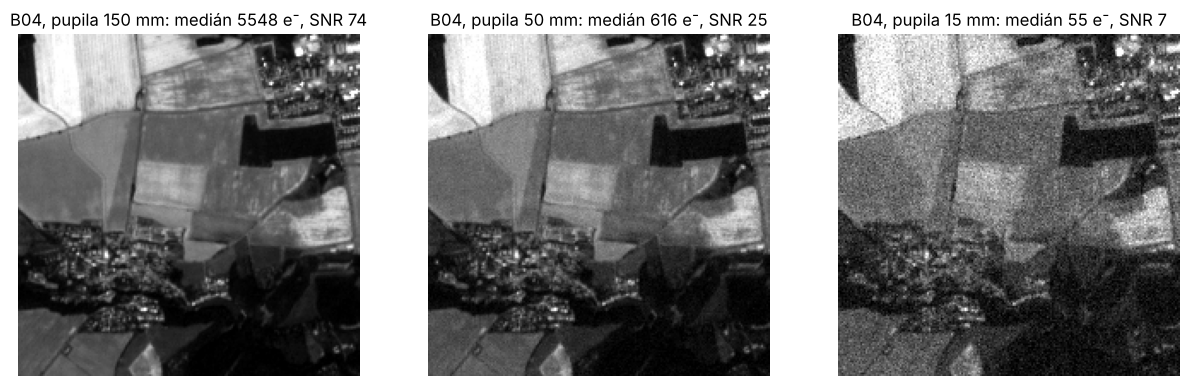

In [5]:
DIAMETERS = [0.150, 0.050, 0.015]    # ◀ parametr: průměry pupily k porovnání (m)
rng = np.random.default_rng(1)
L4 = rad["B04"][:200, :200]
bid, gsd = BANDS["B04"]
fig, ax = plt.subplots(1, len(DIAMETERS), figsize=(5 * len(DIAMETERS), 5))
for a, D in zip(ax, DIAMETERS):
    N = photons(L4, info[bid]["lambda_um"], info[bid]["width_um"], gsd, A=np.pi * (D / 2) ** 2)
    img = rng.poisson(N)                                                      # fotony přicházejí náhodně (Poissonovo rozdělení)
    a.imshow(img, cmap="gray", vmin=np.percentile(img, 1), vmax=np.percentile(img, 99))
    a.set_title(f"B04, pupila {D * 1000:.0f} mm: medián {np.median(N):.0f} e⁻, SNR {np.sqrt(np.median(N)):.0f}"); a.axis("off")
plt.show()

> **✏️ Úkol 3.** Pupila se zmenší třikrát (150 → 50 mm). Kolikrát klesne N a kolikrát SNR? Při jakém průměru pupily by SNR mediánu v B04 kleslo pod 10? Ověř změnou `DIAMETERS`.

*Tvoje odpověď:* 

## 4. Dron proti družici

Pro dron počítáme se stejným pásmem B04 a stejnou září, protože scéna je stejná. Doba expozice je tu nejdelší možná, aby se obraz za letu nerozmazal o víc než jeden pixel (pixel / rychlost). Parametry dronu jsou orientační, odpovídají malé multispektrální kameře.

In [6]:
DRONE = dict(D=0.003, H=100.0, gsd=0.05, speed=8.0)   # ◀ parametr: dron: pupila (m), výška letu (m), pixel na zemi (m), rychlost (m/s), orientačně
bid, gsd = BANDS["B04"]
Lmed = float(np.median(rad["B04"]))
cmp = {}
for label, D, H, g, t in [("Sentinel-2 MSI", D_PUPIL, H_ORBIT, gsd, gsd / v_ground),
                          ("dron", DRONE["D"], DRONE["H"], DRONE["gsd"], DRONE["gsd"] / DRONE["speed"])]:
    Ap, om = np.pi * (D / 2) ** 2, (g / H) ** 2
    N = photons(Lmed, info[bid]["lambda_um"], info[bid]["width_um"], g, A=Ap, H=H, t=t)
    cmp[label] = {"plocha pupily (cm²)": Ap * 1e4, "prostorový úhel pixelu (sr)": om, "A·Ω (m²·sr)": Ap * om, "expozice (ms)": t * 1000, "N (e⁻)": N, "SNR √N": np.sqrt(N)}
pd.DataFrame(cmp).T.style.format("{:.3g}")

,plocha pupily (cm²),prostorový úhel pixelu (sr),A·Ω (m²·sr),expozice (ms),N (e⁻),SNR √N
Sentinel-2 MSI,177,1.62e-10,2.86e-12,1.51,4.09e+03,64
dron,0.0707,2.5e-07,1.77e-12,6.25,1.05e+04,102


> **✏️ Úkol 4.** Pupila dronu má asi 2500krát menší plochu než pupila MSI, a přesto je počet fotoelektronů srovnatelný, dokonce vyšší. Vysvětli to pomocí součinu A·Ω a doby expozice. Co se stane s N, když dron poletí dvakrát výš se stejnou kamerou (pixel se zvětší dvakrát)?

*Tvoje odpověď:* 

## 5. Slučování pixelů a kvantování

Sloučením n × n pixelů se sečtou fotoelektrony, signál roste s n², šum s n, SNR tedy s n. Na konci porovnáme fotonový šum s krokem kvantování: hodnota v L1C je celé číslo (DN) a jeden krok DN odpovídá určitému počtu elektronů.

In [7]:
bid, _ = BANDS["B04"]
N10 = np.median(rad["B04_N"])
rows = []
for n in [1, 2, 3, 6]:                    # sloučení n × n pixelů 10 m (n = 2 odpovídá pixelu 20 m)
    rows.append({"pixel (m)": 10 * n, "N (e⁻)": N10 * n * n, "SNR": np.sqrt(N10 * n * n)})
print(pd.DataFrame(rows).round(0).to_string(index=False))
# kvantování: krok jednoho DN v elektronech
step_rho = 1 / Q
step_L = step_rho * info[bid]["E0"] * U * np.cos(np.radians(SZA)) / np.pi
step_e = photons(step_L, info[bid]["lambda_um"], info[bid]["width_um"], 10)
print(f"jeden DN v B04 = {step_e:.1f} e⁻ (při ETA = {ETA}); šum kvantování = krok/√12 = {step_e / np.sqrt(12):.1f} e⁻, šum fotonů v mediánu = {np.sqrt(N10):.0f} e⁻")

 pixel (m)   N (e⁻)   SNR
        10   4091.0  64.0
        20  16362.0 128.0
        30  36815.0 192.0
        60 147258.0 384.0
jeden DN v B04 = 4.9 e⁻ (při ETA = 0.3); šum kvantování = krok/√12 = 1.4 e⁻, šum fotonů v mediánu = 64 e⁻


> **✏️ Úkol 5.** Kolikrát vzroste SNR, když 10m pixely sloučíš do 60 m? Co tím ztratíš? Je kvantování L1C pro přesnost hodnot důležité, nebo převládá fotonový šum? Co by se stalo, kdyby se odrazivost ukládala jen s 8 bity (krok 1/255)?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Změň `H_ORBIT` na 500 km a `D_PUPIL` tak, aby SNR zůstalo stejné. Porovnej výsledek s menšími družicemi pro pozorování Země, o kterých něco víš.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA; L1C z veřejného archivu Google Cloud (`gcp-public-data-sentinel-2`). Licence: [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice), volné užití s uvedením zdroje.
- ESA: *Sentinel-2 MSI Instrument*, technický průvodce (https://sentinel.esa.int/web/sentinel/technical-guides/sentinel-2-msi/msi-instrument).
- The multispectral instrument of the Sentinel2 program. *Proc. SPIE* 10566, 105660H (ICSO 2008). https://doi.org/10.1117/12.2308278
- Konstanty h a c: v SI od roku 2019 přesně definované hodnoty, převzaté z `scipy.constants`.

### Jak citovat

OpenSkyLab (2026). Švihadlo a fotony, pokročilá verze: kolik fotonů zachytí pixel Sentinelu-2 a dronu [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*